In [13]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv()

DB_USER = os.getenv("DB_USER", "postgres")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST", "localhost")
DB_PORT = os.getenv("DB_PORT", "5432")
DB_NAME = os.getenv("DB_NAME", "violencia_genero_db")

# Conexión a PostgreSQL (Docker)
engine = create_engine(f"postgresql+psycopg2://{os.getenv('DB_USER', 'postgres')}:{os.getenv('DB_PASSWORD')}@{os.getenv('DB_HOST', 'localhost')}:{os.getenv('DB_PORT', '5432')}/{os.getenv('DB_NAME', 'violencia_genero_db')}")

# Cargar tabla raw
df_raw = pd.read_sql("SELECT * FROM raw_violencia_genero;", engine)

print(f"Total registros en Staging: {len(df_raw)}")
print("\nRegistros por Fuente:")
print(df_raw['fuente'].value_counts())

# Diagnóstico de Nulos
print("\nTop 10 Columnas con más nulos:")
print((df_raw.isnull().sum() / len(df_raw) * 100).sort_values(ascending=False).head(10))

# Diagnóstico del campo hora para justificar 'turno'
print("\nFormatos detectados en 'hora_hecho':")
print(df_raw['hora_hecho'].value_counts().head(10))

Total registros en Staging: 22105

Registros por Fuente:
fuente
Historico_Bucaramanga      17104
API_Datos_Gov_Socrata       5000
Scraping_Geoportal_DANE        1
Name: count, dtype: int64

Top 10 Columnas con más nulos:
hora_hecho        51.766569
nom_upgd          25.329111
orden             22.623841
semana            22.623841
area              22.623841
con_fin           22.623841
pac_hos           22.623841
version           22.623841
def_naturaleza    22.623841
edad_agre         22.623841
dtype: float64

Formatos detectados en 'hora_hecho':
hora_hecho
(18:00 a 20:59)    991
12:00:00 a. m.     850
(15:00 a 17:59)    723
(21:00 a 23:59)    681
(12:00 a 14:59)    678
(09:00 a 11:59)    649
Sin información    601
(06:00 a 08:59)    393
10:00:00 a. m.     282
08:00:00 a. m.     267
Name: count, dtype: int64


In [12]:
# Análisis de nulos sobre la tabla raw general
nulos = df_raw.isnull().sum()
nulos_pct = (nulos / len(df_raw)) * 100
df_calidad = pd.DataFrame({'Total_Nulos': nulos, 'Porcentaje_Nulos': nulos_pct})
print("Top 10 columnas con más valores nulos:\n", df_calidad.sort_values(by='Porcentaje_Nulos', ascending=False).head(10))

# Evaluación del campo 'hora_hecho' para la reducción de redundancia
print("\nMuestra de formatos en la columna 'hora_hecho':")
print(df_raw['hora_hecho'].value_counts().head(10))

Top 10 columnas con más valores nulos:
                 Total_Nulos  Porcentaje_Nulos
hora_hecho            11443         51.766569
nom_upgd               5599         25.329111
orden                  5001         22.623841
semana                 5001         22.623841
area                   5001         22.623841
con_fin                5001         22.623841
pac_hos                5001         22.623841
version                5001         22.623841
def_naturaleza         5001         22.623841
edad_agre              5001         22.623841

Muestra de formatos en la columna 'hora_hecho':
hora_hecho
(18:00 a 20:59)    991
12:00:00 a. m.     850
(15:00 a 17:59)    723
(21:00 a 23:59)    681
(12:00 a 14:59)    678
(09:00 a 11:59)    649
Sin información    601
(06:00 a 08:59)    393
10:00:00 a. m.     282
08:00:00 a. m.     267
Name: count, dtype: int64


--- DISTRIBUCIÓN DE CASOS POR JORNADA/TURNO ---
          turno  total_casos  porcentaje
0  NO REPORTADO      12044.0       54.49
1        MAÑANA       3823.0       17.29
2         TARDE       2639.0       11.94
3         NOCHE       1814.0        8.21
4     MADRUGADA       1785.0        8.08


/tmp/ipykernel_7217/2032065442.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(


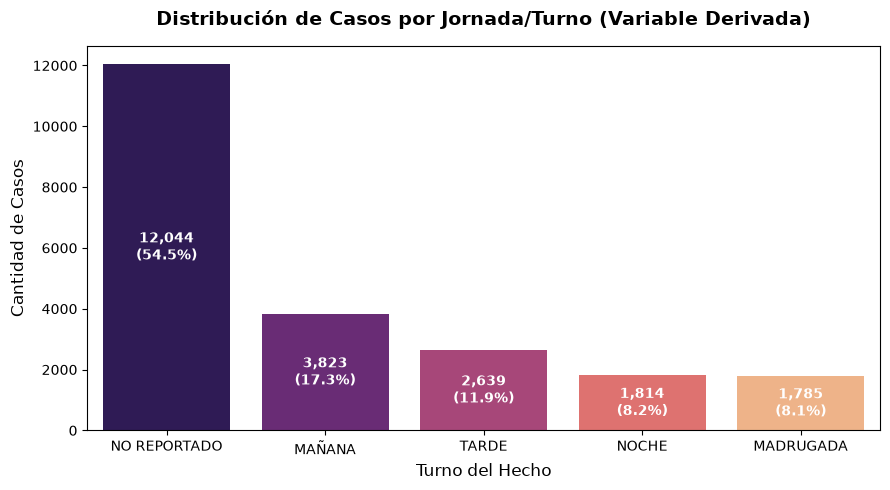

In [11]:
query_jornadas = """
SELECT 
    j.turno,
    SUM(f.cantidad_casos) AS total_casos,
    ROUND((SUM(f.cantidad_casos) * 100.0 / (SELECT COUNT(*) FROM "Fact_Violencia")), 2) AS porcentaje
FROM "Fact_Violencia" f
JOIN "Dim_Jornada" j ON f.id_jornada_sk = j.id_jornada_sk
GROUP BY j.turno
ORDER BY total_casos DESC;
"""

df_jornadas = pd.read_sql(query_jornadas, engine)
print("--- DISTRIBUCIÓN DE CASOS POR JORNADA/TURNO ---")
print(df_jornadas)

plt.figure(figsize=(9, 5))
ax1 = sns.barplot(
    data=df_jornadas, 
    x="turno", 
    y="total_casos", 
    palette="magma"
)

plt.title("Distribución de Casos por Jornada/Turno (Variable Derivada)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Turno del Hecho", fontsize=12)
plt.ylabel("Cantidad de Casos", fontsize=12)

# Mostrar el porcentaje sobre cada barra
for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        pct = (height / df_jornadas['total_casos'].sum()) * 100
        ax1.annotate(f'{int(height):,}\n({pct:.1f}%)',
                     (p.get_x() + p.get_width() / 2., height / 2),
                     ha='center', va='center', fontsize=10, color='white', fontweight='bold')

plt.tight_layout()
plt.show()


--- TOP 15 MUNICIPIOS CON MAYOR NÚMERO DE CASOS ---
   nombre_departamento nombre_municipio  total_casos
0            SANTANDER      BUCARAMANGA      17183.0
1            ANTIOQUIA         MEDELLIN      16997.0
2               BOYACA            TUNJA      16694.0
3               BOYACA         SOGAMOSO      16688.0
4            SANTANDER  BARRANCABERMEJA      16688.0
5                CESAR       VALLEDUPAR      16687.0
6            SANTANDER    FLORIDABLANCA      16672.0
7              CORDOBA         MONTERIA      16668.0
8               ARAUCA           ARAUCA      16667.0
9            SANTANDER            GIRON      16665.0
10           SANTANDER      PIEDECUESTA      16659.0
11           SANTANDER          SAN GIL      16647.0
12              ARAUCA             TAME      16646.0
13           SANTANDER          LEBRIJA      16645.0
14           ATLANTICO  PUERTO COLOMBIA      16642.0


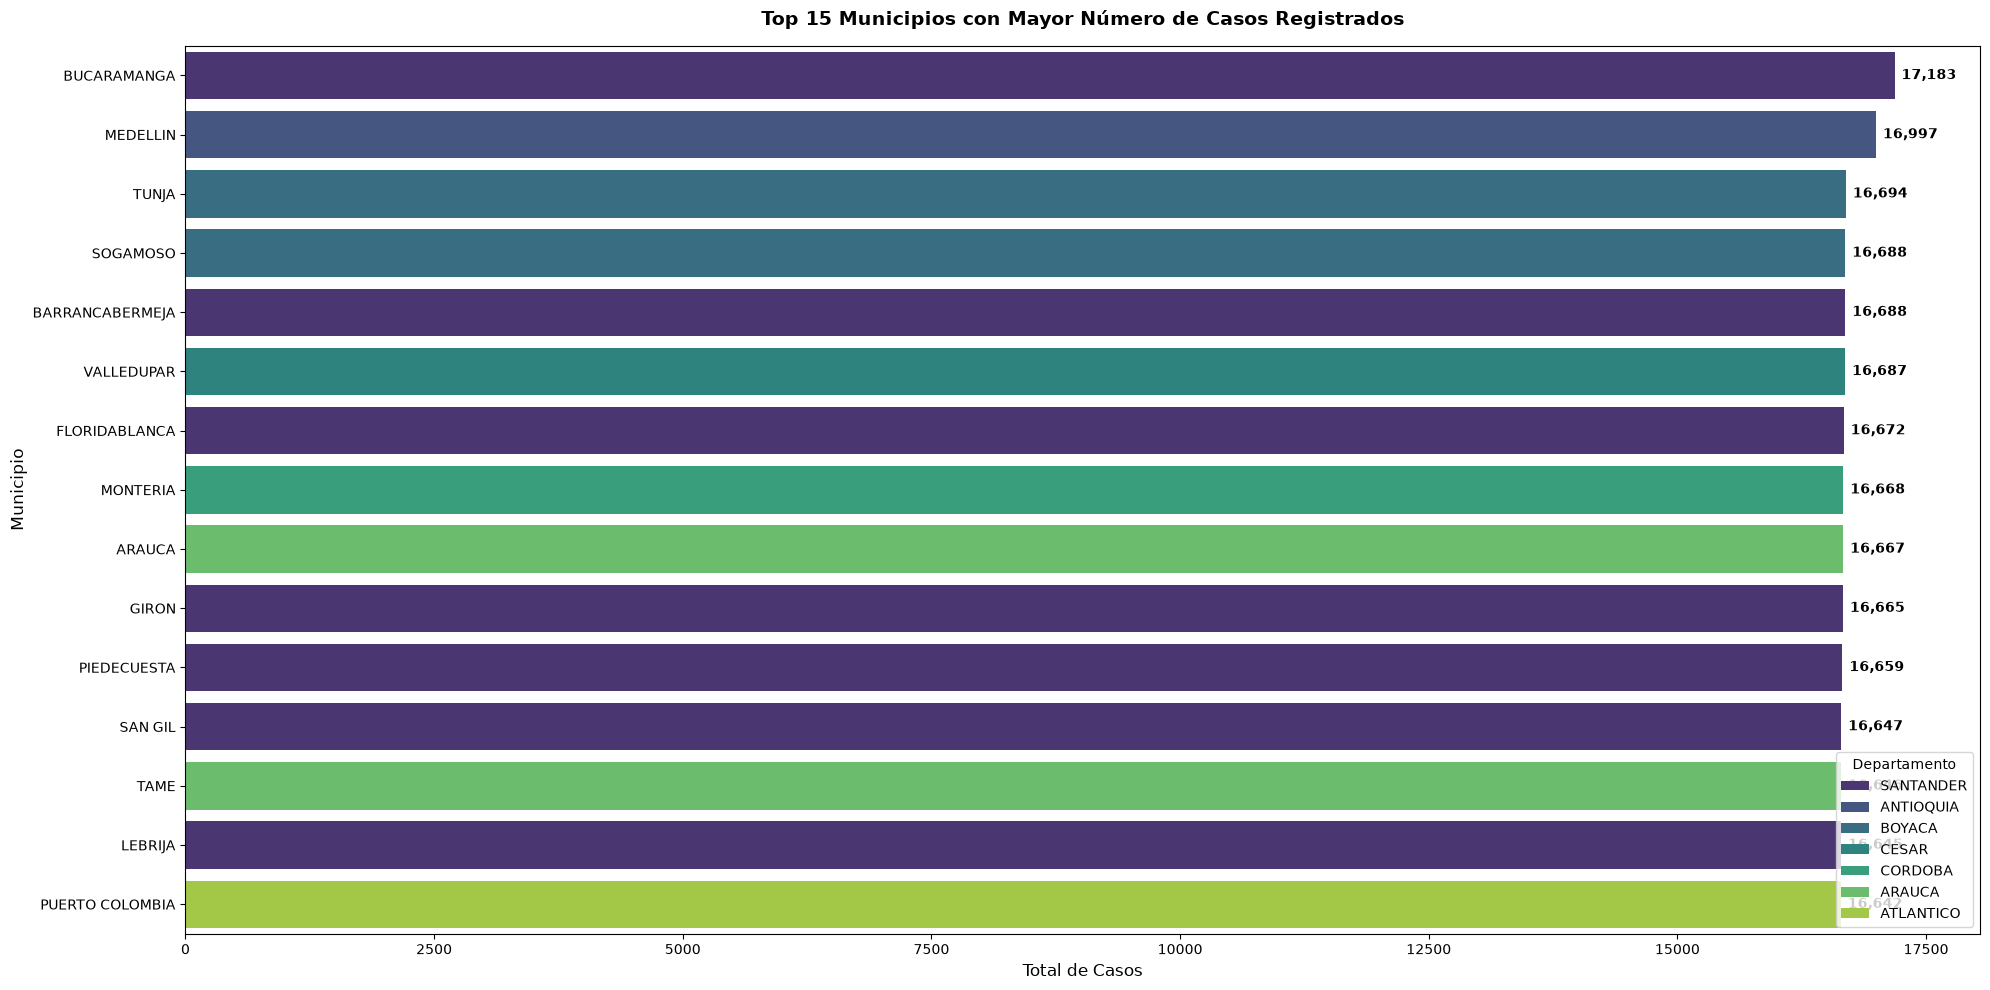

In [9]:
query_ubicaciones = """
SELECT 
    u.nombre_departamento,
    u.nombre_municipio,
    SUM(f.cantidad_casos) AS total_casos
FROM "Fact_Violencia" f
JOIN "Dim_Ubicacion" u ON f.id_ubicacion_sk = u.id_ubicacion_sk
GROUP BY u.nombre_departamento, u.nombre_municipio
ORDER BY total_casos DESC
LIMIT 15;
"""

df_ubicaciones = pd.read_sql(query_ubicaciones, engine)
print("\n--- TOP 15 MUNICIPIOS CON MAYOR NÚMERO DE CASOS ---")
print(df_ubicaciones)

plt.figure(figsize=(20, 10))
ax2 = sns.barplot(
    data=df_ubicaciones, 
    x="total_casos", 
    y="nombre_municipio", 
    hue="nombre_departamento",
    dodge=False,
    palette="viridis"
)

plt.title("Top 15 Municipios con Mayor Número de Casos Registrados", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Total de Casos", fontsize=12)
plt.ylabel("Municipio", fontsize=12)
plt.legend(title="Departamento", loc="lower right")

# Etiquetas de valor en las barras
for p in ax2.patches:
    width = p.get_width()
    if width > 0:
        ax2.annotate(f'{int(width):,}',
                     (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


--- PERFIL DE VICTIMIZACIÓN EN MUJERES (CRUCE MULTIDIMENSIONAL) ---
    sexo              ciclo_vida parentesco_agresor   turno  total_casos
0  MUJER       (29 A 59) ADULTEZ        HERMANO (A)   NOCHE        106.0
1  MUJER       (29 A 59) ADULTEZ        HERMANO (A)   TARDE         89.0
2  MUJER       (29 A 59) ADULTEZ        HERMANO (A)  MAÑANA         87.0
3  MUJER       (29 A 59) ADULTEZ           HIJO (A)   TARDE         85.0
4  MUJER  (12 A 17) ADOLESCENCIA              PADRE   NOCHE         74.0
5  MUJER       (29 A 59) ADULTEZ           HIJO (A)   NOCHE         73.0
6  MUJER      (18 A 28) JUVENTUD        HERMANO (A)   TARDE         72.0
7  MUJER       (29 A 59) ADULTEZ           HIJO (A)  MAÑANA         62.0
8  MUJER  (12 A 17) ADOLESCENCIA              MADRE   NOCHE         57.0
9  MUJER      (18 A 28) JUVENTUD        HERMANO (A)   NOCHE         54.0


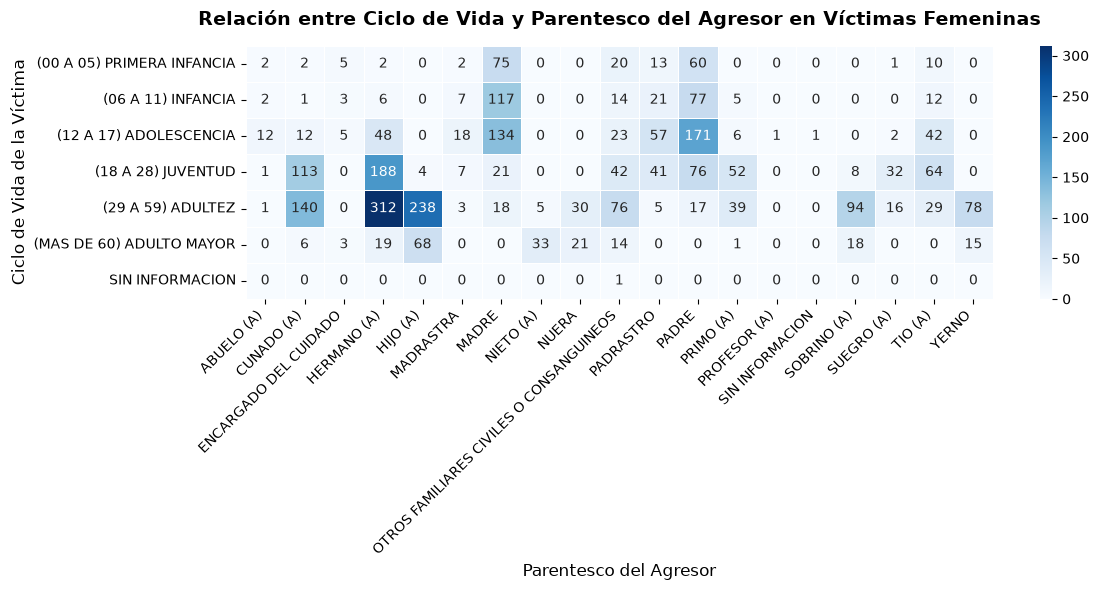

In [14]:
query_multidimensional = """
SELECT 
    v.sexo,
    v.ciclo_vida,
    tv.parentesco_agresor,
    j.turno,
    SUM(f.cantidad_casos) AS total_casos
FROM "Fact_Violencia" f
JOIN "Dim_Victima" v ON f.id_victima_sk = v.id_victima_sk
JOIN "Dim_TipoViolencia" tv ON f.id_tipo_violencia_sk = tv.id_tipo_violencia_sk
JOIN "Dim_Jornada" j ON f.id_jornada_sk = j.id_jornada_sk
WHERE v.sexo = 'MUJER'
GROUP BY v.sexo, v.ciclo_vida, tv.parentesco_agresor, j.turno
ORDER BY total_casos DESC
LIMIT 10;
"""

df_multi = pd.read_sql(query_multidimensional, engine)
print("\n--- PERFIL DE VICTIMIZACIÓN EN MUJERES (CRUCE MULTIDIMENSIONAL) ---")
print(df_multi)

# Preparar matriz pivote para el heatmap
df_heatmap_data = pd.read_sql("""
    SELECT 
        v.ciclo_vida,
        tv.parentesco_agresor,
        SUM(f.cantidad_casos) AS total_casos
    FROM "Fact_Violencia" f
    JOIN "Dim_Victima" v ON f.id_victima_sk = v.id_victima_sk
    JOIN "Dim_TipoViolencia" tv ON f.id_tipo_violencia_sk = tv.id_tipo_violencia_sk
    WHERE v.sexo = 'MUJER' AND tv.parentesco_agresor != 'NO REPORTADO'
    GROUP BY v.ciclo_vida, tv.parentesco_agresor
""", engine)

pivot_heatmap = df_heatmap_data.pivot(index="ciclo_vida", columns="parentesco_agresor", values="total_casos").fillna(0)

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_heatmap, annot=True, fmt=".0f", cmap="Blues", cbar=True, linewidths=0.5)

plt.title("Relación entre Ciclo de Vida y Parentesco del Agresor en Víctimas Femeninas", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Parentesco del Agresor", fontsize=12)
plt.ylabel("Ciclo de Vida de la Víctima", fontsize=12)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

A PARTIR DE ESTE MENSAJE ESTÁN EL EDA QUE HICIMOS LA ENTREGA PASADA, NO SÉ SI SE DEJA O NO. LO DE ARRIBA ES LO QUE LEIDY CONSULTÓ PARA VER SI HABIA FUNCIONADO LA INGESTA Y LA TRANSFORMACIÓN

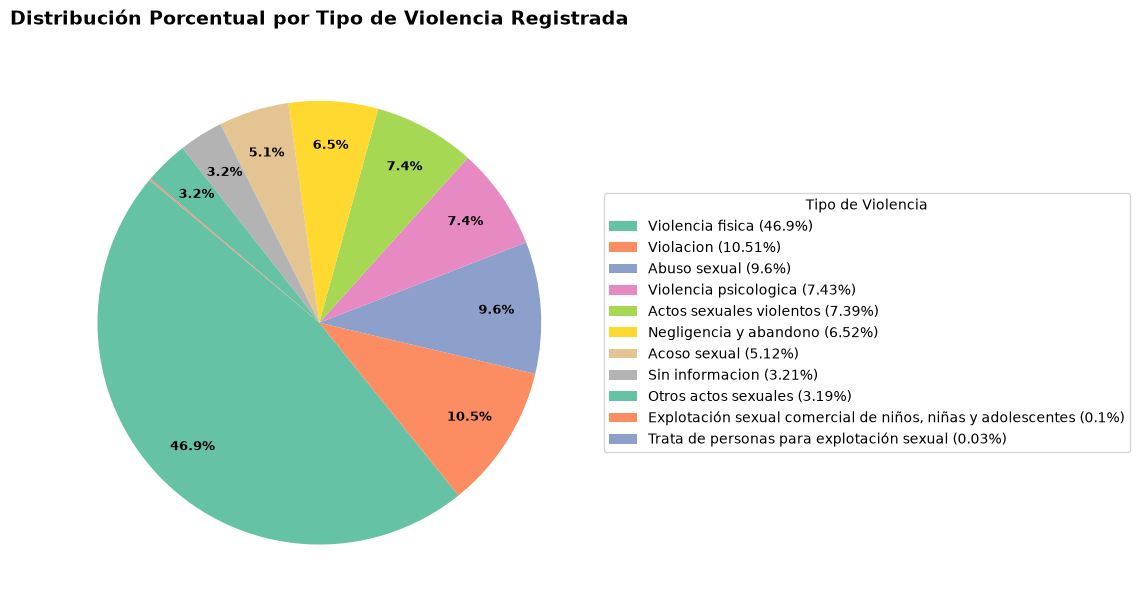

,tipo_violencia,total_casos,porcentaje_total
0,Violencia fisica,3692,46.90
1,Violacion,827,10.51
2,Abuso sexual,756,9.60
3,Violencia psicologica,585,7.43
4,Actos sexuales violentos,582,7.39
5,Negligencia y abandono,513,6.52
6,Acoso sexual,403,5.12
7,Sin informacion,253,3.21
8,Otros actos sexuales,251,3.19
9,"Explotación sexual comercial de niños, niñas y...",8,0.10


In [2]:
output_dir = '../Graficas/graficas_primera_entrega' if os.path.exists('../Graficas/graficas_primera_entrega') else 'Docs/Graficas/graficas_primera_entrega'
os.makedirs(output_dir, exist_ok=True)

query_kpi = "SELECT * FROM vista_kpi_tipo_violencia ORDER BY total_casos DESC;"
df_kpi = pd.read_sql(query_kpi, engine)

plt.figure(figsize=(10, 7))


def autopct_format(values):
    def my_format(pct):
        return f'{pct:.1f}%' if pct > 1.5 else ''
    return my_format

wedges, texts, autotexts = plt.pie(
    df_kpi['total_casos'], 
    autopct=autopct_format(df_kpi['total_casos']),
    startangle=140, 
    colors=sns.color_palette('Set2', len(df_kpi)),
    pctdistance=0.8,
    textprops={'fontsize': 9, 'color': 'black', 'weight': 'bold'}
)


legend_labels = [f'{row["tipo_violencia"]} ({row["porcentaje_total"]}%)' for _, row in df_kpi.iterrows()]
plt.legend(
    wedges, 
    legend_labels, 
    title="Tipo de Violencia", 
    loc="center left", 
    bbox_to_anchor=(1, 0, 0.5, 1), 
    fontsize=10
)

plt.title('Distribución Porcentual por Tipo de Violencia Registrada', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()

# Guardar y mostrar
plt.savefig(os.path.join(output_dir, '01_distribucion_tipo_violencia_torta.png'), dpi=300, bbox_inches='tight')
plt.show()

df_kpi

Distribución de Violencia: La violencia física representa casi la mitad de los registros (46.9%), seguida por delitos sexuales (20.1% entre violación y abuso).

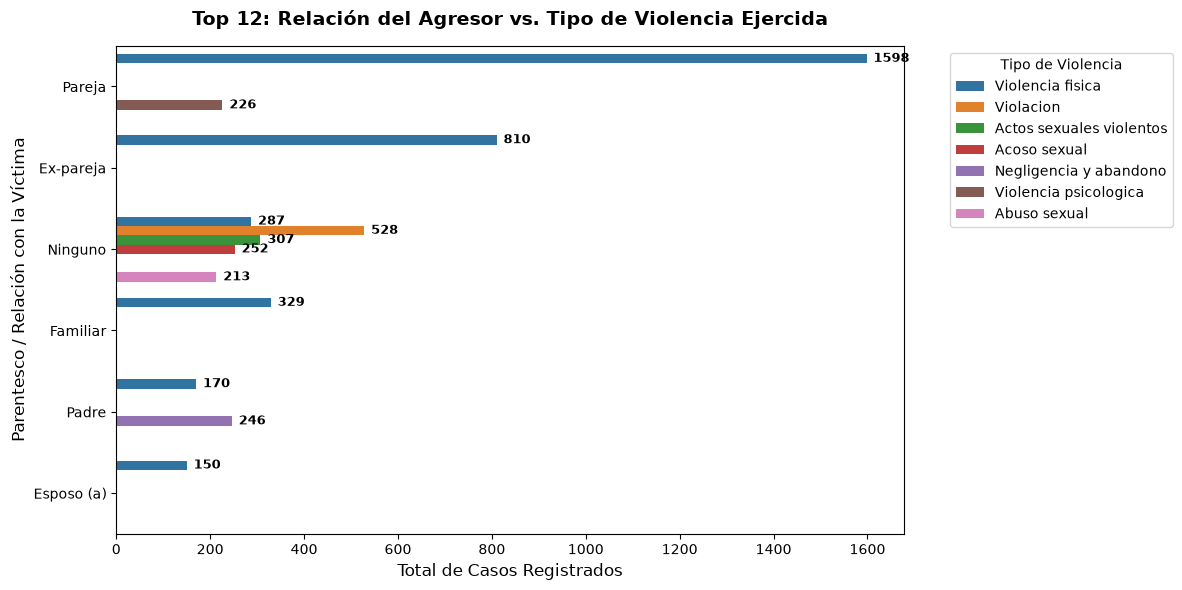

,relacion_agresor,tipo_violencia,total_casos
0,Pareja,Violencia fisica,1598
1,Ex-pareja,Violencia fisica,810
2,Ninguno,Violacion,528
3,Familiar,Violencia fisica,329
4,Ninguno,Actos sexuales violentos,307
5,Ninguno,Violencia fisica,287
6,Ninguno,Acoso sexual,252
7,Padre,Negligencia y abandono,246
8,Pareja,Violencia psicologica,226
9,Ninguno,Abuso sexual,213


In [3]:
output_dir = '../Graficas/graficas_primera_entrega' if os.path.exists('../Graficas/graficas_primera_entrega') else 'Docs/Graficas/graficas_primera_entrega'
os.makedirs(output_dir, exist_ok=True)

query_agresor = "SELECT * FROM vista_eda_agresor_violencia ORDER BY total_casos DESC LIMIT 12;"
df_agresor = pd.read_sql(query_agresor, engine)

plt.figure(figsize=(12, 6))
bars = sns.barplot(
    data=df_agresor, 
    x='total_casos', 
    y='relacion_agresor', 
    hue='tipo_violencia', 
    palette='tab10'
)


for p in bars.patches:
    width = p.get_width()
    if width > 0: 
        bars.annotate(
            f'{int(width)}',
            (width, p.get_y() + p.get_height() / 2.),
            ha='left', va='center',
            xytext=(5, 0),
            textcoords='offset points',
            fontsize=9,
            fontweight='bold'
        )

plt.title('Top 12: Relación del Agresor vs. Tipo de Violencia Ejercida', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Total de Casos Registrados', fontsize=12)
plt.ylabel('Parentesco / Relación con la Víctima', fontsize=12)
plt.legend(title='Tipo de Violencia', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.tight_layout()


plt.savefig(os.path.join(output_dir, '02_agresor_vs_tipo_violencia.png'), dpi=300, bbox_inches='tight')
plt.show()


df_agresor

Entorno del Agresor: La mayoría de agresiones provienen de personas pertenecientes al círculo cercano o intrafamiliar.

/tmp/ipykernel_40009/85312335.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(data=df_ciclo, x='ciclo_vida', y='total_casos', palette='Purples_r')


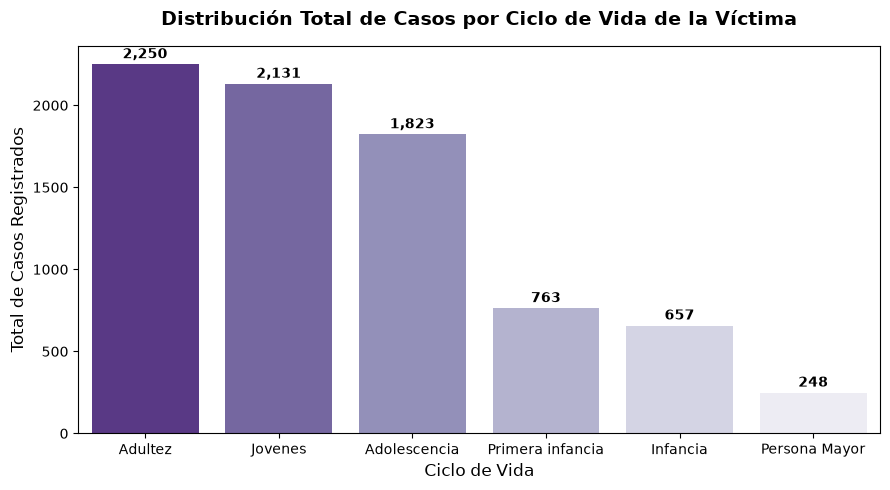

,ciclo_vida,total_casos
1,Adultez,2250
3,Jovenes,2131
0,Adolescencia,1823
5,Primera infancia,763
2,Infancia,657
4,Persona Mayor,248


In [4]:
output_dir = '../Graficas/graficas_primera_entrega' if os.path.exists('../Graficas/graficas_primera_entrega') else 'Docs/Graficas/graficas_primera_entrega'
os.makedirs(output_dir, exist_ok=True)

query_perfil = "SELECT * FROM vista_eda_perfil_tiempo;"
df_perfil = pd.read_sql(query_perfil, engine)

df_ciclo = df_perfil.groupby('ciclo_vida')['total_casos'].sum().reset_index().sort_values(by='total_casos', ascending=False)

plt.figure(figsize=(9, 5))
bars = sns.barplot(data=df_ciclo, x='ciclo_vida', y='total_casos', palette='Purples_r')

for p in bars.patches:
    bars.annotate(
        f'{int(p.get_height()):,}', 
        (p.get_x() + p.get_width() / 2., p.get_height()), 
        ha='center', va='center', 
        xytext=(0, 7), 
        textcoords='offset points',
        fontweight='bold',
        fontsize=10
    )

plt.title('Distribución Total de Casos por Ciclo de Vida de la Víctima', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ciclo de Vida', fontsize=12)
plt.ylabel('Total de Casos Registrados', fontsize=12)
plt.tight_layout()

plt.savefig(os.path.join(output_dir, '03_casos_por_ciclo_vida.png'), dpi=300, bbox_inches='tight')
plt.show()

df_ciclo

Ciclo de Vida: Entre la adolescencia y la adultez concentran la mayor cantidad de registros reportados.